### TEL354 - Minería de datos
# Clase 13: Introduction to Neural Networks
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
from Clase13 import *

# Inspiración biológica de las Redes Neuronales

- Las redes neuronales artificiales están inspiradas en el funcionamiento del cerebro humano.
- Los componentes básicos se asemejan a las neuronas biológicas.

<div align="center">
    <img src="img/Biological-Neuron-versus-Artificial-Neural-Network.png" alt="" width="80%" align="center" />
</div>

# Las famosas Redes Neuronales

* **Árboles de Decisión**: ajustan varias funciones constantes, e.g. $f(x) = a$
* **Redes Neuronales**: ajustan (app) varias funciones no-lineales, e.g. $f(x) = exp(-(ax + b))$

<div align="center">
    <img src="img/ann.png" alt="" width="50%" align="center" />
</div>

# El Perceptrón de una capa (Single-Layer Perceptron, SLP)

<div align="center">
    <img src="img/perceptron.png" alt="" width="30%" align="center" />
</div>

$$ z = f(\mathbf{x} \cdot \mathbf{w} + b) = f \left(\sum_{i=1}^n x_iw_i + b \right) $$

# Término de Bias (Sesgo)

- El bias permite que la neurona se active incluso si todas las entradas son cero.
- Mejora la flexibilidad del modelo permitiendo "desplazar" la función de activación.

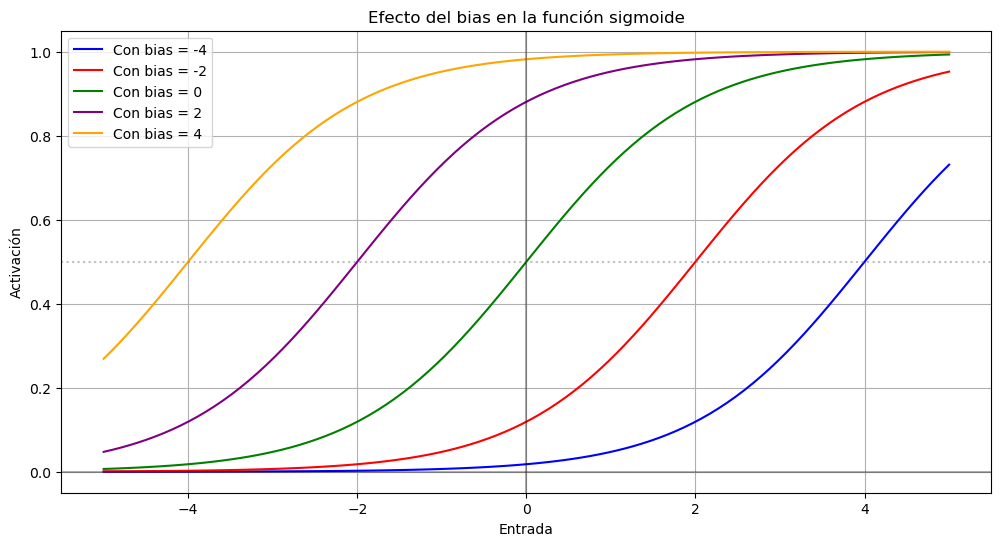

In [2]:
visualizar_efecto_bias([-4, -2, 0, 2, 4])

# Función de activación

En la fórmula anterior, $f$ es una función de activación, cuyo propósito principal es introducir no linealidad en la red, permitiendo que ésta sea capaz de aprender y modelar relaciones complejas entre las variables de entrada y salida. Las siguientes son las más comunes:

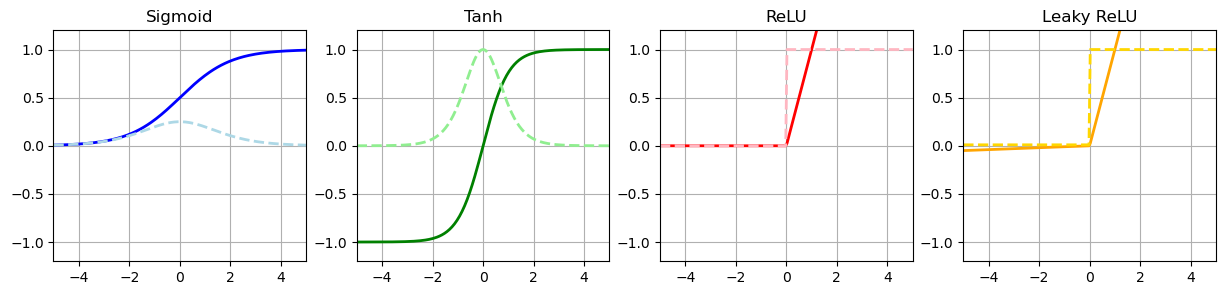

In [3]:
plot_activation_functions(derivatives=True)

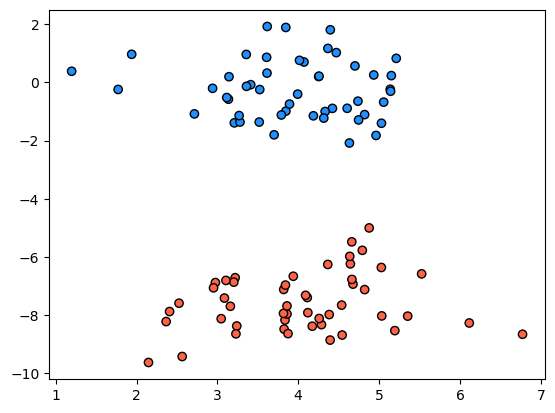

In [4]:
X, y = make_blobs(random_state=754, cluster_std=1, centers=2)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=ListedColormap(['dodgerblue', 'tomato']), ec="k")
plt.show()

In [5]:
slp = Sequential()

In [6]:
slp.add(Dense(units=1, input_shape=(2,), activation='sigmoid'))

In [7]:
slp.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

In [8]:
slp_history = slp.fit(X, y, epochs=100, verbose=0)

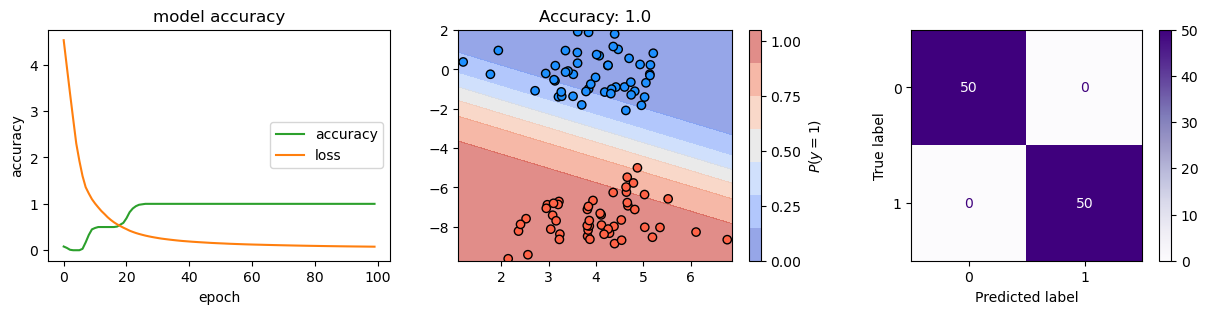

In [9]:
plot_results(X, y, slp, slp_history)

# Datos que no son linealmente separables

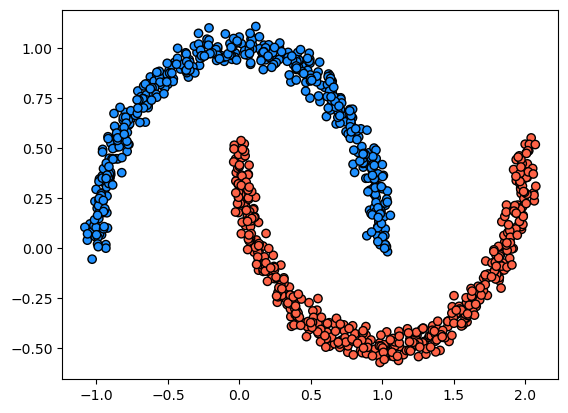

In [10]:
X_moons, y_moons = make_moons(n_samples=1000, random_state=27, noise=0.04)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap=ListedColormap(['dodgerblue', 'tomato']), ec="k")
plt.show()

# Single-Layer Perceptron sobre datos no separables linealmente

In [11]:
slp_moons = Sequential()
slp_moons.add(Dense(units=1, input_shape=(2,), activation='sigmoid'))
slp_moons.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])
slp_moons_history = slp_moons.fit(X_moons, y_moons, verbose=0, epochs=100)

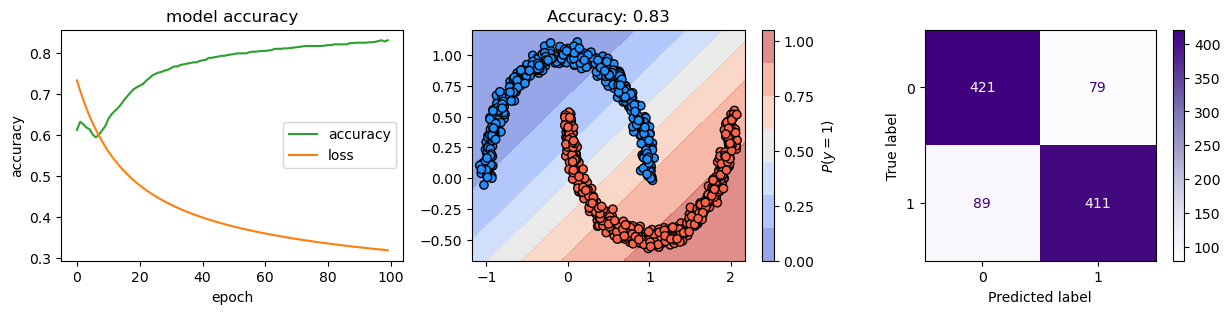

In [12]:
plot_results(X_moons, y_moons, slp_moons, slp_moons_history)

# El Perceptrón multicapa (Multi-Layer Perceptron, MLP)

<div align="center">
    <img src="img/layers.png" alt="" width="50%" align="center" />
</div>

El resultado de cada capa pasa por su propia función de activación:

$$ y = f(f(f(x \cdot W_1)\cdot W_2)\cdot W_3) $$

# Backpropagation (Retropropagación)

- Algoritmo para entrenar redes neuronales: Mecanismo de ajuste de pesos basado en el error.
- Forward pass: calcula predicciones. Calcular error (diferencia entre predicción y target). Backward pass: propagar el error "hacia atrás". Actualizar pesos según gradientes.
    
<div align="center">
    <img src="img/backpropagation.jpg" alt="" width="50%" align="center" />
</div>

In [13]:
mlp = Sequential()

In [14]:
mlp.add(Dense(8, input_shape=(2,), activation='tanh'))
mlp.add(Dense(4, activation='tanh'))
mlp.add(Dense(2, activation='tanh'))
mlp.add(Dense(1, activation='sigmoid'))

In [15]:
mlp.compile(SGD(learning_rate=0.01), 'binary_crossentropy', metrics=['accuracy'])
mlp_history = mlp.fit(X_moons, y_moons, verbose=0, epochs=300)

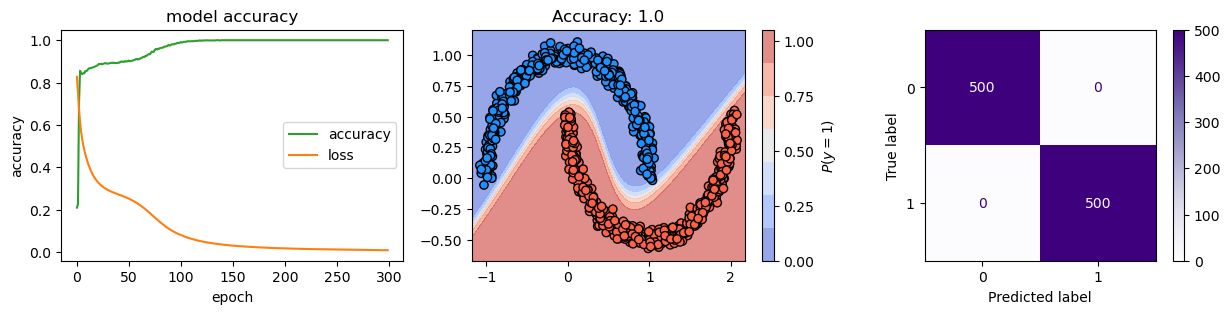

In [16]:
plot_results(X_moons,y_moons, mlp, mlp_history)

# Clasificación Multi-Clase

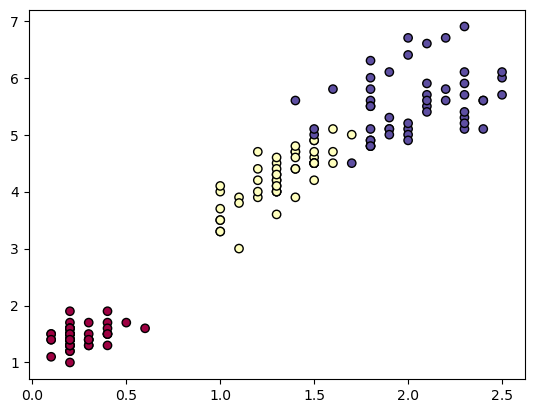

In [17]:
dfIris = sns.load_dataset("iris") 
X_iris = dfIris[['petal_width','petal_length']].to_numpy()
y_iris = dfIris.species
y_cat = y_iris.map({'setosa':0, 'versicolor':1, 'virginica':2})
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=y_cat, ec="k", cmap=plt.cm.Spectral)
plt.show()

# Softmax

- También conocida como activación multinomial.
- Esta función es usada por lo general en la capa de salida de la red.
- Resuelve el problema de más de 2 clases que la activación Sigmoide no logra.
- Asegura que las probabilidades de cada clase sumen 1.

<div align="center">
    <img src="img/softmax.jpg" alt="" width="30%" align="center" />
</div>

En deep learning, el término *logits layer* se usa para la última capa de neuronas en tarea de clasificación.

In [18]:
model = Sequential()
model.add(Dense(128, input_shape=(2,), activation='tanh'))
model.add(Dense(64, activation='tanh'))
model.add(Dense(32, activation='tanh'))
model.add(Dense(16, activation='tanh'))
model.add(Dense(3, activation='softmax'))
model.compile(SGD(learning_rate=0.01), 'categorical_crossentropy', metrics=['accuracy'])

In [19]:
history = model.fit(X_iris, to_categorical(y_cat), verbose=0, epochs=300)

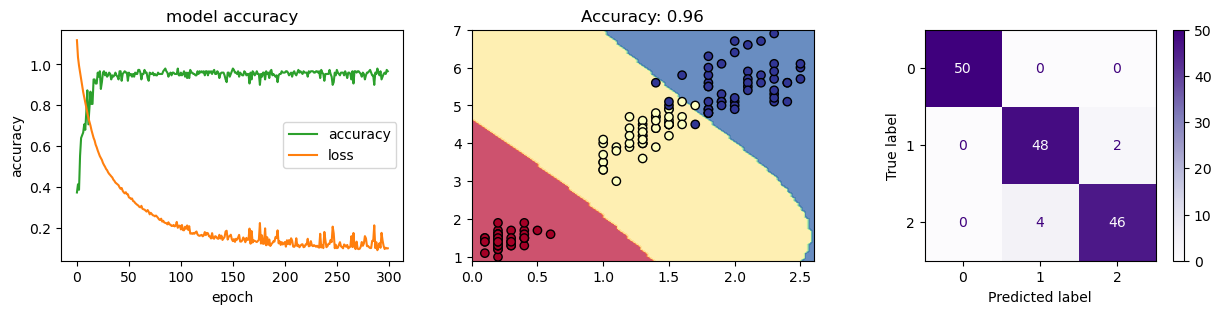

In [20]:
plot_results(X_iris,y_cat,model,history)